# Prevención de Mortalidad Fetal e Hipoxia mediante Machine Learning

### Integrantes: Dylan Luisjuan Rico, Leonardo Alejando Ambriz Mendoza, Derek Lugo Aguirre, Ricardo Chavez Altamirano

## Objetivo de la práctica

Analizar el tiempo de ejecución y la complejidad computacional de los algoritmos **K-Nearest Neighbors (KNN)** y **Regresión Logística One-vs-Rest (OvR)** desarrollados para el proyecto de cardiotocografía. Se comparan las implementaciones propias con las de `scikit-learn`, utilizando diferentes tamaños de muestra del mismo conjunto de datos.

El análisis se concentra exclusivamente en los tiempos de **entrenamiento (`fit`)** y **predicción (`predict`)**, su crecimiento al aumentar el número de registros y las optimizaciones utilizadas por la biblioteca. No se calculan métricas de clasificación como Accuracy, F1, Recall o AUC, ya que no forman parte del objetivo de esta materia.

### Organización

1. Carga y preparación de los datos.
2. Implementaciones propias de KNN y Regresión Logística OvR.
3. Medición de tiempos de las implementaciones propias y de `scikit-learn`.
4. Cálculo teórico de la complejidad asintótica.
5. Ajuste empírico, gráficas e interpretación de las optimizaciones.


### Librerias usadas y Carga de los datos

In [45]:
import numpy as np
import pandas as pd
from collections import Counter
import time
import sklearn
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression as SklearnLogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from scipy.optimize import curve_fit

print(f"NumPy: {np.__version__}" )
print(f"scikit-learn: {sklearn.__version__}")

NumPy: 2.5.4
scikit-learn: 1.9.1


In [46]:
url = 'https://raw.githubusercontent.com/DylanRico007/fetal-health-classifier-ml/refs/heads/main/data/processed/CTG_clean.csv'
df = pd.read_csv(url)

X = df.drop(columns=["NSP"]).to_numpy(dtype=float)
y = df["NSP"].to_numpy(dtype=int)

print(" Datos del proyecto: ")
print(f"Registros: {X.shape[0]}")
print(f"Características: {X.shape[1]}")
print(f"Clases disponibles: {np.unique(y)}")

 Datos del proyecto: 
Registros: 2126
Características: 21
Clases disponibles: [1 2 3]


## **Muestras para el analisis**


In [47]:
fracciones = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
datasets_por_fraccion = {}

#Se genera una permutacion por clase para conservar la proporción de NSP
rng = np.random.default_rng(42)
indices_por_clase = {
    clase: rng.permutation(np.where(y == clase)[0])
    for clase in np.unique(y)
}

#Division de muestras y de entrenamiento
for frac in fracciones:
    indices = np.concatenate([
        indices_clase[:max(2, round(len(indices_clase) * frac))]
        for indices_clase in indices_por_clase.values()
    ])

    X_sub, y_sub = X[indices], y[indices]
    #Division 80% / 20%
    X_train_raw, X_test_raw, y_train, y_test = train_test_split(
        X_sub,
        y_sub,
        test_size=0.20,
        random_state=42,
        stratify=y_sub
    )

    #z Score: los parámetros se obtienen únicamente de X_train
    media = X_train_raw.mean(axis=0)
    desviacion = X_train_raw.std(axis=0)
    desviacion = np.where(desviacion == 0, 1.0, desviacion)

    X_train = (X_train_raw - media) / desviacion
    X_test = (X_test_raw - media) / desviacion

    datasets_por_fraccion[frac] = {
        "X_train": X_train,
        "X_test": X_test,
        "y_train": y_train,
        "y_test": y_test
    }

#Tabla con resultados
resumen = pd.DataFrame([
    {
        "Fracción": f"{int(frac * 100)}%",
        "N total": len(datos["y_train"]) + len(datos["y_test"]),
        "N train": len(datos["y_train"]),
        "M test": len(datos["y_test"])
    }
    for frac, datos in datasets_por_fraccion.items()
])

display(resumen)

,Fracción,N total,N train,M test
0,10%,214,171,43
1,20%,425,340,85
2,30%,637,509,128
3,40%,850,680,170
4,50%,1064,851,213
5,60%,1276,1020,256
6,70%,1487,1189,298
7,80%,1701,1360,341
8,90%,1914,1531,383
9,100%,2126,1700,426


## **Implementacion de algoritmos**

### KNN del proyecto

In [48]:
class KNNClassifier:

    def __init__(self, n_neighbors=5):
        self.n_neighbors = n_neighbors
        self.X_train = None
        self.y_train = None

    def fit(self, X, y):
        self.X_train = X
        self.y_train = y
        return self

    def _euclidean_distance(self, a, b):
        return np.sqrt(np.sum((a - b) ** 2))

    def _predict_one(self, x):
        distances = np.array([
            self._euclidean_distance(x, x_train)
            for x_train in self.X_train
            ])
        nearest_indices = np.argsort(distances)[:self.n_neighbors]
        nearest_labels = self.y_train[nearest_indices]
        return Counter(nearest_labels.tolist()).most_common(1)[0][0]

    def predict(self, X):
        return np.array([self._predict_one(x) for x in X])

### KNN: Calculo de complejidad teorica

Siendo:

-    **N** - Numero de Registros de entrenamiento
-    **M** - Numero de Registros de que se van a clasificar
-    **p** - Numero de caracteristicas del dataset
-    **k** - Numero de vecinos

### KNN implementado de scikit-learn

la mima cuestion con 

In [49]:
def crear_knn_sklearn():
    return KNeighborsClassifier(
        n_neighbors=5,
        metric="euclidean",
        algorithm="auto",
        n_jobs=-1
    )

#Configuracion para los datos del dataset
knn_prueba = crear_knn_sklearn()
datos_completos = datasets_por_fraccion[1.0]
knn_prueba.fit(datos_completos["X_train"], datos_completos["y_train"])

print(f"Características de entrada: {X.shape[1]}")
print("Configuración: algorithm='auto', metric='euclidean'")

Características de entrada: 21
Configuración: algorithm='auto', metric='euclidean'


### KNN de scikit-learn: algoritmo y complejidad

En la documentación de `scikit-learn` se indica que `algorithm="auto"` selecciona la busqueda por fuerza bruta cuando las caracteristicas (p) es mayor que 15. El dataset tiene 21 caracteristicas, por lo cual en este caso se utiliza la busqueda **brute-force**.

Esta calcula distancias entre las consultas y los registros de entrenamiento mediante las rutinas de distancias por pares de la biblioteca.
El costo para consultas (M), registros (N) y caracteristicas (p) es:

$$
T_{predict}(N,M)=O(MNp)
$$

Con (p = 21) fijo y (M) proporcional a (N), el orden conjunto se aproxima a **$O(N^2)$**. La biblioteca reduce el costo practico mediante rutinas optimizadas de distancias por pares, reduccion para obtener los vecinos (k) y ejecucion paralela cuando se solicita con `n_jobs = -1`. Para contraste, el KNN del proyecto ordena completamente las distancias de cada consulta.

## Regresion Logistica: Implementacion del proyecto

La clase de Regresion Logistica usada en el proyecto es binaria. Para mantener las categoria de NSP se usa la estrategia **One-vs-Rest (OvR)**: Se entrenan 3 clasificadores, cada uno especializado en reconcer una clase frente a las restantes. Para determinar la clase final se usa la que tenga el mayor puntaje sigmoide.

La primera clase es binaria corresponde al proyecto. La segunda clase es un envoltorio que produce en una sola clase la construccion de los 3 modelos independientes hechos en el proyecto.

In [50]:
class LogisticRegression:

    def __init__(self, learning_rate=0.1, n_iterations=2000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.weights = None
        self.biases = None

    def sigmoide(self, z):
        return 1 / (1 + np.exp(-z))

    def predict_proba(self, X):
        return self.sigmoide(X.dot(self.weights) + self.biases)

    def predict(self, X, threshold=0.3): 
        return (self.predict_proba(X) >= threshold).astype(int)

    def compute_cost(self, X, y):
        eps = 1e-15
        p = np.clip(self.predict_proba(X), eps, 1 - eps)
        return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

    def compute_gradients(self, X, y):
        n_samples = X.shape[0]
        errors = self.predict_proba(X) - y
        dw = (1 / n_samples) * X.T.dot(errors)
        db = (1 / n_samples) * np.sum(errors)
        return dw, db

    def fit(self, X, y):
        n_features = X.shape[1]
        self.weights = np.zeros(n_features)
        self.biases = 0.0

        for _ in range(self.n_iterations):
            dw, db = self.compute_gradients(X, y)
            self.weights -= self.learning_rate * dw
            self.biases -= self.learning_rate * db
        return self


 #Combina tres clasificadores binarios de Regresión Logística
class LogisticRegressionOvR:
   
    def __init__(self, learning_rate=0.1, n_iterations=2000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.classes_ = None
        self.models_ = []

    def fit(self, X, y):
        self.classes_ = np.unique(y)
        self.models_ = []

        for clase in self.classes_:
            y_binario = (y == clase).astype(int)
            modelo = LogisticRegression(
                learning_rate=self.learning_rate,
                n_iterations=self.n_iterations
            )
            modelo.fit(X, y_binario)
            self.models_.append(modelo)
        return self

    def predict(self, X):
        puntajes = np.column_stack([
            modelo.predict_proba(X) for modelo in self.models_
        ])
        return self.classes_[np.argmax(puntajes, axis=1)]

## Regresion Logistica OvR del proyecto: calculo de complejidad teorica

Sean:

- **(N)** los registros de entrenamiento
- **(M)** los registros de prueba
- **(p)** las caracteristicas
- **(C)** las clases
- **(I)** las iteraciones del descenso de gradiente.

En el **entrenamiento** cada itereacion del clasificador binaro se calcula la combinacion lineal **$Xw+b$** y el gradiente. Ambas operaciones recorren la matriz de datos y tienen costo proporicona a (Np). Al hacer uso de OvR se repite el proces para tras clases, por lo tanto:

$$
T_{fit}(N)=O(CINp)
$$

Debido a que (C), (I) y (p) se mantienen fijos en el experimento, el crecimiento con respecto al numero de registros es lineal: **$O(N)$**.

En la **prediccion** cada uno de los tres clasificadores calcula un producto entre las observaciones (M) y sus pesos (p). La seleccion del mayor puntaje agrega un costro computacional a (CM):

$$
T_{predict}(M)=O(CMp)
$$

Con (C = 3) y (p = 21) fijos, la prediccion crece linealmente con el numero de registros de prueba: $O(M)$

### Regresion Logistica OvR de scikit-learn

Comparando el mismo esquema multiclase, se usa `OneVsRestClassifier` con `LogisticRegression` y el solver `1bfgs`, manteniendo `max_iter=2000`, como en el notebook de modelado. A diferencia de nuestra clase del proyecto, `scikit-learn` aplica regularización L2 por defecto.

In [51]:
def crear_logistica_sklearn():
    base = SklearnLogisticRegression(
        solver="lbfgs",
        max_iter=2000,
        random_state=42
    )
    return OneVsRestClassifier(base)

## Regresion Logistica de scikit-learn: optimización y complejidad

`OneVsRestClassifier` ajusta un clasificador binario por cada clase. En `LogisticRegression`, el solver seleccionado es **L-BFGS**, un método cuasi-Newton de memoria limitada. La cantidad de iteraciones depende del criterio de convergencia (`tol`) y está limitada por `max_iter`; por ello, no existe un número fijo de iteraciones igual al de nuestra implementación propia.

Si $I_{LBFGS}$ representa las iteraciones utilizadas por cada clasificador, el costo dominante del ajuste puede expresarse de manera aproximada como:

$$
T_{fit}(N)=O(CI_{LBFGS}Np)
$$

El numero efectivo de iteraciones se debe interpretar junto con el tiempo medido. En el rango de datos de esta práctica se ajustará también una función lineal para describir el crecimiento observado, sin presentarla como una prueba universal del comportamiento del solver.

En predicción, cada modelo calcula puntajes para (M) registros y (p) características:

$$
T_{predict}(M)=O(CMp)
$$

Por lo tanto, con un número fijo de clases y características, el costo de predicción es lineal en \(M\). Las ventajas prácticas de `scikit-learn` provienen del solver L-BFGS, del uso de operaciones numéricas optimizadas y de sus rutinas de validación y manejo de matrices; estas optimizaciones reducen el tiempo observado, pero no eliminan el costo de procesar las observaciones.

## Funcion para medir los tiempos

Se mide por separado `fit` y  `predict`, usando 7 repeticiones por tamaño de muestra. Primero se ejecuta una corrida de calentamiento antes de cronometrar. Se presenta el promedio y la mediana en milisegundos, usando esta ultima para la graficacion y ajustes.

In [52]:
REPETICIONES = 7


def medir_tiempos_modelo(crear_modelo_fn, datos, repeticiones=REPETICIONES):
    X_train = datos["X_train"]
    y_train = datos["y_train"]
    X_test = datos["X_test"]

    #Calentamiento
    #no se incluye en los tiempos reportados
    modelo = crear_modelo_fn()
    modelo.fit(X_train, y_train)
    modelo.predict(X_test)

    tiempos_fit = []
    tiempos_predict = []

    for _ in range(repeticiones):
        modelo = crear_modelo_fn()

        inicio = time.perf_counter()
        modelo.fit(X_train, y_train)
        tiempos_fit.append((time.perf_counter() - inicio) * 1000)

        inicio = time.perf_counter()
        modelo.predict(X_test)
        tiempos_predict.append((time.perf_counter() - inicio) * 1000)

    return {
        "Fit promedio (ms)": np.mean(tiempos_fit),
        "Fit mediana (ms)": np.median(tiempos_fit),
        "Predict promedio (ms)": np.mean(tiempos_predict),
        "Predict mediana (ms)": np.median(tiempos_predict)
    }

## Medicion de tiempos
### Implementaciones propias y de biblioteca

Se usan los mismos tamaños de muestra, participaciones y datos estandarizados para los 4 casos. Los parametros principales se mantienen iguales al proyecto: KNN con 5 vecinos y Regresion Logistica OvR con 3 clasificadore y 2000 iteraciones en la implementacion 

In [53]:
modelos = {
    "KNN propio": lambda: KNNClassifier(n_neighbors=5),
    "KNN scikit-learn": crear_knn_sklearn,
    "Logística OvR propia": lambda: LogisticRegressionOvR(
        learning_rate=0.1, n_iterations=2000
    ),
    "Logística OvR scikit-learn": crear_logistica_sklearn
}

resultados = []

for frac, datos in datasets_por_fraccion.items():
    for nombre, crear_modelo in modelos.items():
        medicion = medir_tiempos_modelo(crear_modelo, datos)
        resultados.append({
            "Fracción": f"{int(frac * 100)}%",
            "Modelo": nombre,
            "N train": len(datos["y_train"]),
            "M test": len(datos["y_test"]),
            **medicion
        })

resultados_tiempos = pd.DataFrame(resultados)
print("Mediciones terminadas.")
display(resultados_tiempos.round(4))

Mediciones terminadas.


,Fracción,Modelo,N train,M test,Fit promedio (ms),Fit mediana (ms),Predict promedio (ms),Predict mediana (ms)
0,10%,KNN propio,171,43,0.0009,0.0007,33.1808,33.4267
1,10%,KNN scikit-learn,171,43,10.2983,0.7376,42.6292,12.0525
2,10%,Logística OvR propia,171,43,117.6780,118.2995,0.0525,0.0530
3,10%,Logística OvR scikit-learn,171,43,21.6256,21.2985,0.5036,0.5011
4,20%,KNN propio,340,85,0.0007,0.0007,122.3938,119.5233
5,20%,KNN scikit-learn,340,85,0.7690,0.6747,26.9362,17.5611
6,20%,Logística OvR propia,340,85,137.4132,139.3130,0.0569,0.0554
7,20%,Logística OvR scikit-learn,340,85,29.4525,25.8858,0.5824,0.5238
8,30%,KNN propio,509,128,0.0007,0.0007,249.5945,252.1135
9,30%,KNN scikit-learn,509,128,6.2231,0.7208,5.5033,5.3854


## Resumen de tiempos

Una tabla para ver mas claramente la comparacion entre el entrenamineto y la prediccion de cada modelo

In [54]:
resumen_tiempos = resultados_tiempos.pivot_table(
    index=["Fracción", "N train", "M test"],
    columns="Modelo",
    values=["Fit mediana (ms)", "Predict mediana (ms)"]
)

display(resumen_tiempos.round(4))

Fit mediana (ms)                   \
Modelo                        KNN propio KNN scikit-learn   
Fracción N train M test                                     
10%      171     43               0.0007           0.7376   
100%     1700    426              0.0011           0.6994   
20%      340     85               0.0007           0.6747   
30%      509     128              0.0007           0.7208   
40%      680     170              0.0011           0.6787   
50%      851     213              0.0011           0.7231   
60%      1020    256              0.0010           0.7930   
70%      1189    298              0.0007           0.7748   
80%      1360    341              0.0006           1.4984   
90%      1531    383              0.0013           1.4269   

                                                                         \
Modelo                  Logística OvR propia Logística OvR scikit-learn   
Fracción N train M test                                                   
10%      171     43                 118.2995                    21.2985   
100%     1700    426                329.4316                    44.2898   
20%      340     85                 139.3130                    25.8858   
30%      509     128                170.1400                    27.7560   
40%      680     170                190.7643                    28.7689   
50%      851     213                216.5248                    30.2192   
60%      1020    256                230.5764                    30.2306   
70%      1189    298                235.7218                    34.9016   
80%      1360    341                292.4744                    39.2723   
90%      1531    383                325.6045                    35.1037   

                        Predict mediana (ms)                   \
Modelo                            KNN propio KNN scikit-learn   
Fracción N train M test                                         
10%      171     43                  33.4267          12.0525   
100%     1700    426               2890.5006           3.5554   
20%      340     85                 119.5233          17.5611   
30%      509     128                252.1135           5.3854   
40%      680     170                439.8821           6.4453   
50%      851     213                679.0750           6.6805   
60%      1020    256               1065.5316          34.6088   
70%      1189    298               1375.6403          11.5956   
80%      1360    341               1896.0463           4.2476   
90%      1531    383               2592.6968           4.7047   

                                                                         
Modelo                  Logística OvR propia Logística OvR scikit-learn  
Fracción N train M test                                                  
10%      171     43                   0.0530                     0.5011  
100%     1700    426                  0.0859                     0.5680  
20%      340     85                   0.0554                     0.5238  
30%      509     128                  0.0654                     0.5619  
40%      680     170                  0.0665                     0.5474  
50%      851     213                  0.0701                     0.5030  
60%      1020    256                  0.0737                     0.5191  
70%      1189    298                  0.0727                     0.5224  
80%      1360    341                  0.0792                     0.6329  
90%      1531    383                  0.0871                     0.5962

## Ajuste empirico de las funciones

Se ajustan funciones sencillas a las medianas medidas. Las formas utilizadas corresponden al análisis teórico anterior:

| Modelo y fase | Función de referencia |
|---|---|
| KNN propio – `fit` | Constante, $O(1)$ |
| KNN propio – `predict` | $M N log N$, por el ordenamiento completo de distancias |
| KNN scikit-learn – `fit` | Lineal aproximada en (N), asociada a validación y preparación de datos |
| KNN scikit-learn – `predict` | ($M N$), con ($p$) fijo y búsqueda por fuerza bruta |
| Regresión Logística OvR propia – `fit` | Lineal en $(N$), con ($C$), ($I$) y ($p$) fijos |
| Regresión Logística OvR propia – `predict` | Lineal en ($M$) |
| Regresión Logística OvR scikit-learn – `fit` | Ajuste lineal empírico en ($N$) para el rango medido |
| Regresión Logística OvR scikit-learn – `predict` | Lineal en ($M$) |

El ajuste empírico describe el intervalo de tamaños probado. Un valor bajo de $R^2$ indica que los tiempos obtenidos no siguen de manera clara la función propuesta en este rango; no se debe forzar una conclusión a partir de una curva con poco ajuste.

In [55]:
# Funciones teóricas/empíricas utilizadas para el ajuste.
def modelo_constante(N, c):
    return np.full_like(np.asarray(N, dtype=float), c, dtype=float)


def modelo_lineal(N, a, b):
    return a * np.asarray(N, dtype=float) + b


def modelo_knn_propio(x, a, b):
    N_train, M_test = x
    return a * M_test * N_train * np.log(N_train) + b


def modelo_knn_sklearn(x, a, b):
    N_train, M_test = x
    return a * M_test * N_train + b


def calcular_r2(y_real, y_estimado):
    ss_res = np.sum((y_real - y_estimado) ** 2)
    ss_tot = np.sum((y_real - np.mean(y_real)) ** 2)
    return 1.0 if ss_tot == 0 else 1 - ss_res / ss_tot


N_train = resultados_tiempos[
    resultados_tiempos["Modelo"] == "KNN propio"
]["N train"].to_numpy(dtype=float)
M_test = resultados_tiempos[
    resultados_tiempos["Modelo"] == "KNN propio"
]["M test"].to_numpy(dtype=float)

#
def obtener_tiempos(modelo, columna):
    tabla = resultados_tiempos[resultados_tiempos["Modelo"] == modelo]
    return tabla[columna].to_numpy(dtype=float)


t_knn_fit = obtener_tiempos("KNN propio", "Fit mediana (ms)")
t_knn_predict = obtener_tiempos("KNN propio", "Predict mediana (ms)")
t_knn_sk_fit = obtener_tiempos("KNN scikit-learn", "Fit mediana (ms)")
t_knn_sk_predict = obtener_tiempos("KNN scikit-learn", "Predict mediana (ms)")

t_lr_fit = obtener_tiempos("Logística OvR propia", "Fit mediana (ms)")
t_lr_predict = obtener_tiempos("Logística OvR propia", "Predict mediana (ms)")
t_lr_sk_fit = obtener_tiempos("Logística OvR scikit-learn", "Fit mediana (ms)")
t_lr_sk_predict = obtener_tiempos("Logística OvR scikit-learn", "Predict mediana (ms)")

#Ajustes mediante curve_fit
p_knn_fit, _ = curve_fit(
    modelo_constante, N_train, t_knn_fit,
    p0=[np.median(t_knn_fit)], maxfev=20000
)
p_knn_predict, _ = curve_fit(
    modelo_knn_propio, (N_train, M_test), t_knn_predict,
    p0=[t_knn_predict[-1] / (M_test[-1] * N_train[-1] * np.log(N_train[-1])), 0.0],
    maxfev=20000
)
p_knn_sk_fit, _ = curve_fit(
    modelo_lineal, N_train, t_knn_sk_fit,
    p0=[(t_knn_sk_fit[-1] - t_knn_sk_fit[0]) / (N_train[-1] - N_train[0]), t_knn_sk_fit[0]],
    maxfev=20000
)
p_knn_sk_predict, _ = curve_fit(
    modelo_knn_sklearn, (N_train, M_test), t_knn_sk_predict,
    p0=[t_knn_sk_predict[-1] / (M_test[-1] * N_train[-1]), 0.0],
    maxfev=20000
)
p_lr_fit, _ = curve_fit(
    modelo_lineal, N_train, t_lr_fit,
    p0=[(t_lr_fit[-1] - t_lr_fit[0]) / (N_train[-1] - N_train[0]), t_lr_fit[0]],
    maxfev=20000
)
p_lr_predict, _ = curve_fit(
    modelo_lineal, M_test, t_lr_predict,
    p0=[t_lr_predict[-1] / M_test[-1], 0.0], maxfev=20000
)
p_lr_sk_fit, _ = curve_fit(
    modelo_lineal, N_train, t_lr_sk_fit,
    p0=[(t_lr_sk_fit[-1] - t_lr_sk_fit[0]) / (N_train[-1] - N_train[0]), t_lr_sk_fit[0]],
    maxfev=20000
)
p_lr_sk_predict, _ = curve_fit(
    modelo_lineal, M_test, t_lr_sk_predict,
    p0=[t_lr_sk_predict[-1] / M_test[-1], 0.0], maxfev=20000
)

#Coeficientes de determinacion sobre las observaciones medida
r2 = {
    "KNN propio fit": calcular_r2(t_knn_fit, modelo_constante(N_train, *p_knn_fit)),
    "KNN propio predict": calcular_r2(t_knn_predict, modelo_knn_propio((N_train, M_test), *p_knn_predict)),
    "KNN scikit fit": calcular_r2(t_knn_sk_fit, modelo_lineal(N_train, *p_knn_sk_fit)),
    "KNN scikit predict": calcular_r2(t_knn_sk_predict, modelo_knn_sklearn((N_train, M_test), *p_knn_sk_predict)),
    "Logística propia fit": calcular_r2(t_lr_fit, modelo_lineal(N_train, *p_lr_fit)),
    "Logística propia predict": calcular_r2(t_lr_predict, modelo_lineal(M_test, *p_lr_predict)),
    "Logística scikit fit": calcular_r2(t_lr_sk_fit, modelo_lineal(N_train, *p_lr_sk_fit)),
    "Logística scikit predict": calcular_r2(t_lr_sk_predict, modelo_lineal(M_test, *p_lr_sk_predict))
}

print("--- R² de los ajustes empíricos ---")
for nombre, valor in r2.items():
    print(f"{nombre:28s}: {valor:.4f}")

--- R² de los ajustes empíricos ---
KNN propio fit              : 0.0000
KNN propio predict          : 0.9945
KNN scikit fit              : 0.2881
KNN scikit predict          : 0.0925
Logística propia fit        : 0.9783
Logística propia predict    : 0.9544
Logística scikit fit        : 0.8959
Logística scikit predict    : 0.3642


## Graficas de KNN hecho y de scikit-learn

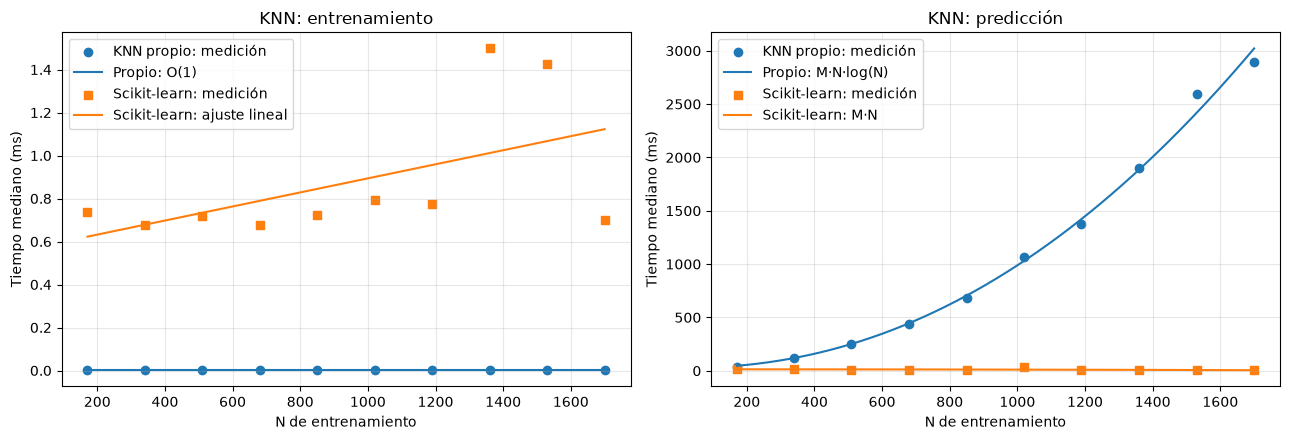

In [56]:
N_suave = np.linspace(N_train.min(), N_train.max(), 200)
M_suave = (M_test / N_train).mean() * N_suave

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

#Entrenamiento KNN
axes[0].scatter(N_train, t_knn_fit, label="KNN propio: medición")
axes[0].plot(N_suave, modelo_constante(N_suave, *p_knn_fit), label="Propio: O(1)")
axes[0].scatter(N_train, t_knn_sk_fit, marker="s", label="Scikit-learn: medición")
axes[0].plot(N_suave, modelo_lineal(N_suave, *p_knn_sk_fit), label="Scikit-learn: ajuste lineal")
axes[0].set_title("KNN: entrenamiento")
axes[0].set_xlabel("N de entrenamiento")
axes[0].set_ylabel("Tiempo mediano (ms)")
axes[0].legend()
axes[0].grid(alpha=0.3)

#Prediccion KNN
axes[1].scatter(N_train, t_knn_predict, label="KNN propio: medición")
axes[1].plot(N_suave, modelo_knn_propio((N_suave, M_suave), *p_knn_predict), label="Propio: M·N·log(N)")
axes[1].scatter(N_train, t_knn_sk_predict, marker="s", label="Scikit-learn: medición")
axes[1].plot(N_suave, modelo_knn_sklearn((N_suave, M_suave), *p_knn_sk_predict), label="Scikit-learn: M·N")
axes[1].set_title("KNN: predicción")
axes[1].set_xlabel("N de entrenamiento")
axes[1].set_ylabel("Tiempo mediano (ms)")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Graficas: Regresion Logistica OvR hecha y de scikit-learn

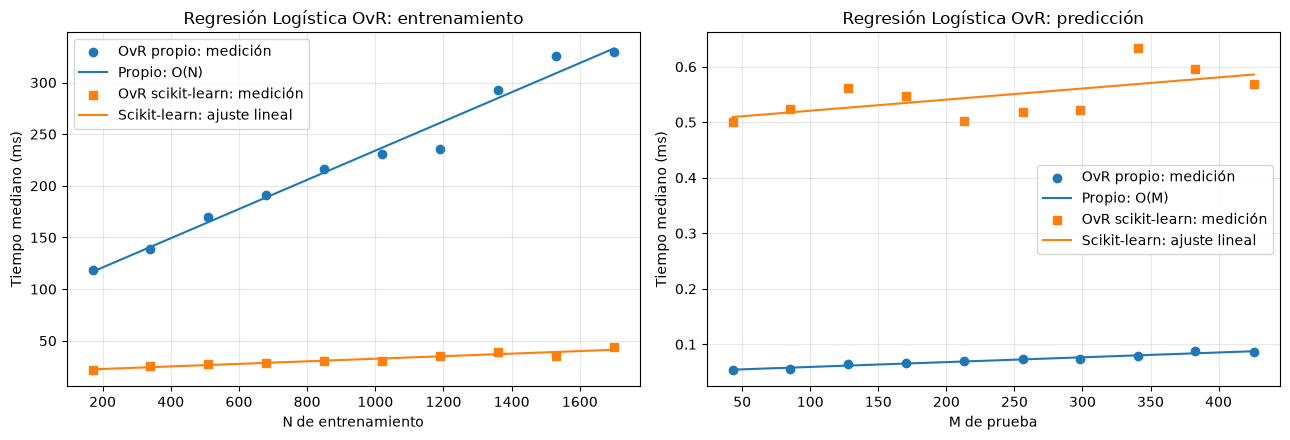

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

#Entrenamiento de Regresion Logística
axes[0].scatter(N_train, t_lr_fit, label="OvR propio: medición")
axes[0].plot(N_suave, modelo_lineal(N_suave, *p_lr_fit), label="Propio: O(N)")
axes[0].scatter(N_train, t_lr_sk_fit, marker="s", label="OvR scikit-learn: medición")
axes[0].plot(N_suave, modelo_lineal(N_suave, *p_lr_sk_fit), label="Scikit-learn: ajuste lineal")
axes[0].set_title("Regresión Logística OvR: entrenamiento")
axes[0].set_xlabel("N de entrenamiento")
axes[0].set_ylabel("Tiempo mediano (ms)")
axes[0].legend()
axes[0].grid(alpha=0.3)

#Prediccion de Regresion Logistica
M_suave = np.linspace(M_test.min(), M_test.max(), 200)
axes[1].scatter(M_test, t_lr_predict, label="OvR propio: medición")
axes[1].plot(M_suave, modelo_lineal(M_suave, *p_lr_predict), label="Propio: O(M)")
axes[1].scatter(M_test, t_lr_sk_predict, marker="s", label="OvR scikit-learn: medición")
axes[1].plot(M_suave, modelo_lineal(M_suave, *p_lr_sk_predict), label="Scikit-learn: ajuste lineal")
axes[1].set_title("Regresión Logística OvR: predicción")
axes[1].set_xlabel("M de prueba")
axes[1].set_ylabel("Tiempo mediano (ms)")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Interpretacion de resultados y optimizaciones

### KNN

- En la implementación propia, `fit` solo almacena las matrices, por lo que su tiempo debe permanecer prácticamente constante. Lo principal aparece en `predict`: se calculan distancias contra todo el conjunto de entrenamiento y se ordenan para seleccionar los cinco vecinos.
- En `scikit-learn`, `algorithm="auto"` selecciona fuerza bruta para las 21 características del conjunto. La búsqueda procesa distancias por pares y aplica una reducción para conservar los vecinos requeridos; además, `n_jobs=-1` permite paralelizar el trabajo.
- La diferencia de tiempo observada entre ambas versiones puede deberse a las rutinas numéricas optimizadas y a la selección de los vecinos sin ordenar completamente todas las distancias. La función asintótica propuesta debe contrastarse con el valor de $R^2$$ y con las gráficas.

### Regresión Logística OvR

- La implementación propia ejecuta 2000 iteraciones por cada uno de los tres clasificadores. En cada iteración calcula predicciones y gradientes mediante operaciones matriciales de NumPy. Por eso, el tiempo de entrenamiento aumenta al crecer ($N$), mientras que la predicción procesa las observaciones de prueba mediante tres productos matriz-vector.
- `scikit-learn` usa el solver L-BFGS, un método cuasi-Newton de memoria limitada. El algoritmo decide cuándo detenerse según la tolerancia y el máximo de iteraciones. La biblioteca también utiliza implementaciones numéricas optimizadas y recomienda matrices en formato C-contiguous para obtener mejor rendimiento.
- L-BFGS puede reducir el número de iteraciones requeridas respecto al descenso de gradiente con una tasa fija. No cambia el hecho de que cada iteración debe procesar los datos; el tiempo final depende también de la convergencia y de la configuración utilizada.

### Alcance del ajuste empírico

Los tiempos dependen del procesador, la memoria, la versión de Python y de las bibliotecas, la carga del sistema y el paralelismo. Los ajustes mediante `curve_fit` describen únicamente el intervalo de tamaños medido. Si un $R^2$ es bajo, no debe afirmarse que la curva valida el orden teórico; en ese caso, se reporta la complejidad derivada del código o de la documentación y se presenta el tiempo como evidencia experimental complementaria.

## 11. Conclusiones

Se analizó el costo temporal de las implementaciones propias de KNN y Regresión Logística OvR, y se compararon con las versiones de `scikit-learn`. El análisis teórico permite explicar dónde se concentra el trabajo de cada algoritmo: en KNN, durante la búsqueda de vecinos de cada observación; en Regresion Logistica, durante las iteraciones necesarias para ajustar los tres clasificadores binarios.

La comparación con la biblioteca debe interpretarse a partir de las optimizaciones realmente utilizadas. Para KNN, las 21 características hacen que `algorithm="auto"` elija búsqueda por fuerza bruta, por lo que no corresponde atribuir el resultado a KD-Tree o Ball-Tree. Para Regresión Logística, L-BFGS modifica el proceso de optimización y el número de iteraciones, mientras que la predicción conserva un costo lineal respecto al número de observaciones consultadas cuando las características y clases se mantienen fijas.

Los tiempos medidos son propios del entorno donde se ejecute este notebook. Las curvas ajustadas sirven para comparar el comportamiento observado, pero no sustituyen el análisis asintótico derivado de las operaciones de cada implementación.

## Referencias

NumPy Developers. (2026). *numpy.argsort* (Versión 2.5) [Documentación de software]. https://numpy.org

NumPy Developers. (2026). *numpy.sort* (Versión 2.5) [Documentación de software]. https://numpy.org

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., y Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research*, *12*, 2825–2830. https://jmlr.org

Scikit-learn Developers. (2026). *LogisticRegression* (Versión 1.9.1) [Documentación de software]. https://scikit-learn.org

Scikit-learn Developers. (2026). *Nearest Neighbors* (Versión 1.9.1) [Documentación de software]. https://scikit-learn.org

UCI Machine Learning Repository. (2010).
Cardiotocography. University of California, Irvine.
https://doi.org/10.24432/C51S4N
